In [157]:
import os

from transformers import AutoFeatureExtractor, AutoModel
import numpy as np
from datasets import load_dataset
import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt
import pandas as pd
import cv2
from PIL import Image
from tqdm import tqdm

In [148]:
base_path = "/mnt/pg-fs01/Current/DB/ObjectDetectionV3"
df = pd.read_csv(os.path.join(base_path, "images.csv"))
df.shape

(1032, 6)

In [149]:
names = df["name"].values
names = np.unique(names)
names.shape

(970,)

In [150]:
def img_by_name(img_name: str, df):
    row = df[df["name"] == img_name]
    pth = os.path.join(base_path, row["batch"].iloc[0], row["folder"].iloc[0], img_name)
    img = cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB)
    return img

In [151]:
model_ckpt = "google/vit-base-patch16-224-in21k"
extractor = AutoFeatureExtractor.from_pretrained(model_ckpt)
model = AutoModel.from_pretrained(model_ckpt)
hidden_dim = model.config.hidden_size


# Data transformation chain.
transformation_chain = T.Compose(
    [
        # We first resize the input image to 256x256 and then we take center crop.
        T.Resize((extractor.size["width"], extractor.size["height"])),
        T.ToTensor(),
        T.Normalize(mean=extractor.image_mean, std=extractor.image_std),
    ]
)


def extract_embeddings(model: torch.nn.Module):
    """Utility to compute embeddings."""
    device = model.device

    def pp(batch):
        images = batch["image"]
        image_batch_transformed = torch.stack(
            [transformation_chain(image) for image in images]
        )
        new_batch = {"pixel_values": image_batch_transformed.to(device)}
        with torch.no_grad():
            embeddings = model(**new_batch).last_hidden_state[:, 0].cpu()
        return {"embeddings": embeddings}

    return pp


def extract_embedding_from_img(img: np.ndarray, model: torch.nn.Module):
    """Utility to extract embeddings from a single image."""
    device = model.device
    img = transformation_chain(img)
    img = img.unsqueeze(0).to(device)
    with torch.no_grad():
        embeddings = model(pixel_values=img).last_hidden_state[:, 0].cpu()
    return embeddings

/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(


In [152]:
extractor.size["width"], extractor.size["height"]

(224, 224)

In [153]:
def compute_scores(emb_one, emb_two):
    """Computes cosine similarity between two vectors."""
    scores = torch.nn.functional.cosine_similarity(emb_one, emb_two)
    return scores.numpy().tolist()


def fetch_similar(image, top_k, all_candidate_embeddings, candidate_ids, device):
    """Fetches the `top_k` similar images with `image` as the query."""
    # Prepare the input query image for embedding computation.
    image_transformed = transformation_chain(image).unsqueeze(0)
    new_batch = {"pixel_values": image_transformed.to(device)}

    # Comute the embedding.
    with torch.no_grad():
        query_embeddings = model(**new_batch).last_hidden_state[:, 0].cpu()

    # Compute similarity scores with all the candidate images at one go.
    # We also create a mapping between the candidate image identifiers
    # and their similarity scores with the query image.
    sim_scores = compute_scores(all_candidate_embeddings, query_embeddings)
    similarity_mapping = dict(zip(candidate_ids, sim_scores))
 
    # Sort the mapping dictionary and return `top_k` candidates.
    similarity_mapping_sorted = dict(
        sorted(similarity_mapping.items(), key=lambda x: x[1], reverse=True)
    )
    id_entries = list(similarity_mapping_sorted.keys())[:top_k]

    ids = list(map(lambda x: int(x.split("_")[0]), id_entries))
    labels = list(map(lambda x: int(x.split("_")[-1]), id_entries))
    return ids, labels

In [158]:
device = "cuda" if torch.cuda.is_available() else "cpu"

embeddings = []
for i in tqdm(names):
    img = img_by_name(i, df)
    embeddings.append(extract_embedding_from_img(Image.fromarray(img), model.to(device)))


distances = np.zeros((len(embeddings), len(embeddings)))
for i in tqdm(range(len(embeddings))):
    for j in range(i, len(embeddings)):
        similarity = compute_scores(embeddings[i], embeddings[j])[0]
        distances[i, j] = similarity
        distances[j, i] = similarity

100%|██████████| 970/970 [00:14<00:00, 65.34it/s] 


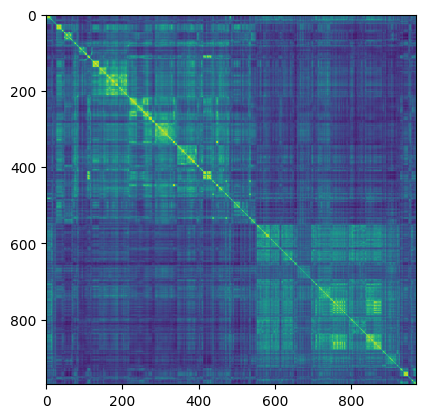

In [159]:
plt.imshow(distances)

In [160]:
np.save("distances_image_similrity.npy", distances)
np.save("names_image_similrity.npy", names)